# 23 – Zwei Wächter unter gleichen Bedingungen: Normalverhaltensmodell gegen Prognose-LSTM

**Zweck:** Im Projekt gibt es zwei Wächter, die melden, wenn sich an einer Station etwas
verändert:

| | Normalverhaltensmodell ([`17`](17_normalverhaltensmodell.ipynb), Seb) | Prognose-LSTM ([`21`](21_prognose_lstm_waechter.ipynb), Dominik) |
|---|---|---|
| Daten | Tageswerte aus Zählerständen | Stundenwerte |
| Erwartung | Kennlinie je Station gegen die Außentemperatur | ein neuronales Netz für alle Stationen: 7 Vortage, Wetter, Vorlauf |
| Kanäle | Abkühlung (kWh/m³), Tagesvolumen | Rücklauf, Nachtdurchfluss |
| Tage | nur Heiztage | alle Tage |
| Alarm | CUSUM, ein Alarm je Veränderung | z ≥ 4 an zwei Tagen hintereinander, ein Alarm je Veränderung |

Beide Notebooks haben ihren Wächter geprüft, aber **nicht gleich**: verschiedene Fenster um
die Begehung, verschiedene Kontrollgruppen, verschiedene Alarmmengen. Die Zahlen „70 %
gegen 53 %“ (NB 17) und „11–17 % gegen 13 %“ (NB 21) lassen sich deshalb nicht
nebeneinanderlegen. Dieses Notebook prüft beide **unter denselben Bedingungen**:

1. **dieselbe Prüfung:** Sebs Verfahren aus NB 17, Abschnitt 11, wird nachgebaut und zuerst
   gegen seine eigenen Zahlen geprüft;
2. **dieselben Stationen und Tage:** nur Stationen und Heiztage, die beide überwachen;
3. **dasselbe Alarmbudget:** Ein Wächter, der öfter alarmiert, trifft automatisch öfter. Die
   Schwelle des LSTM wird deshalb so gewählt, dass es gleich viele Alarme gibt wie bei Seb.

**Voraussetzung:** Notebook 06 und 17 (für `hast_tage.csv` und `normalmodell_*.csv`) und
Notebook 21 (für `prognose_tage.csv`) sind gelaufen.

## 1 · Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", message=".*Data Validation extension.*")
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.load_begehungen import begehungen_mit_zaehler

PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

# Sebs Prüfung (NB 17, Abschnitt 1) - unverändert übernommen
FENSTER_VOR, FENSTER_NACH = 7, 60
MIN_TAGE_IM_FENSTER = 5
KONTROLL_VORLAUF = 60
MIN_KONTROLLEN = 5
AB = pd.Timestamp("2024-06-01")     # ab hier überwacht das LSTM (vorher hat es gelernt)

**Was macht diese Zelle?**
- Lädt die Bibliotheken und den Begehungs-Loader des Teams.
- Übernimmt Sebs Prüfparameter unverändert: Fenster von 7 Tagen vor bis 60 Tage nach der
  Begehung, mindestens 5 überwachte Tage im Fenster, Kontrollstationen ohne eigene Begehung
  in den 60 Tagen davor, mindestens 5 Kontrollstationen je Fall.
- `AB`: Das LSTM hat bis Ende Mai 2024 gelernt. Verglichen wird erst ab Juni 2024, damit
  kein Wächter an Tagen geprüft wird, die er zum Lernen benutzt hat.

## 2 · Die Ausgaben beider Wächter ansehen

In [2]:
seb_alarme = pd.read_csv(PROCESSED / "normalmodell_alarme.csv", parse_dates=["datum", "beginn"])
seb_tage = pd.read_csv(PROCESSED / "normalmodell_tage.csv", parse_dates=["datum"])
seb_stationen = pd.read_csv(PROCESSED / "normalmodell_stationen.csv", index_col="zaehler", parse_dates=["ref_ende"])
seb_treffer = pd.read_csv(PROCESSED / "normalmodell_treffer.csv", parse_dates=["datum"])
print(f"Seb: {len(seb_alarme)} Alarme, {seb_tage['zaehler'].nunique()} Stationen, "
      f"{(seb_stationen['status'] == 'ok').sum()} davon überwacht")
seb_alarme.head()

Seb: 479 Alarme, 89 Stationen, 89 davon überwacht


,zaehler,kanal,datum,richtung,beginn,heiztage_bis_alarm
0,53198226,kwh_pro_m3,2022-12-30,1,2022-12-23,8
1,53198226,kwh_pro_m3,2023-05-04,1,2023-05-01,4
2,53198226,kwh_pro_m3,2023-05-15,-1,2023-05-12,4
3,53198226,kwh_pro_m3,2023-05-19,1,2023-05-19,1
4,53198226,kwh_pro_m3,2023-12-29,1,2023-12-19,11


In [3]:
seb_tage.head()

,zaehler,kanal,datum,t_mittel_c,gemessen,erwartet,residuum,z,referenz,s_plus,s_minus
0,53198226,kwh_pro_m3,2021-11-02,7.4,29.750000,26.346905,3.403095,1.520262,True,NaN,NaN
1,53198226,kwh_pro_m3,2021-11-03,7.3,31.800000,26.356659,5.443341,2.431699,True,NaN,NaN
2,53198226,kwh_pro_m3,2021-11-04,6.8,24.166667,26.405429,-2.238762,-1.000120,True,NaN,NaN
3,53198226,kwh_pro_m3,2021-11-05,6.8,31.000000,26.405429,4.594571,2.052529,True,NaN,NaN
4,53198226,kwh_pro_m3,2021-11-06,3.7,26.375000,26.707801,-0.332801,-0.148672,True,NaN,NaN


**Was man sieht**
- `normalmodell_alarme.csv`: eine Zeile je Alarm mit Station, Kanal, Datum, Richtung
  (+1 = höher, −1 = niedriger als erwartet) und dem geschätzten Beginn der Veränderung.
- `normalmodell_tage.csv`: je Station, Kanal und Heiztag die Erwartung, das Residuum, der
  z-Wert und die beiden CUSUM-Konten. `referenz = True` sind die Tage, aus denen die
  Kennlinie gelernt wurde; überwacht wird erst danach.

In [4]:
lstm = pd.read_csv(PROCESSED / "prognose_tage.csv", parse_dates=["tag"])
print(f"LSTM: {len(lstm):,} Zähler-Tage, {lstm['zaehler'].nunique()} Stationen, {lstm['alarm'].sum()} Alarme insgesamt")
lstm.head()

LSTM: 58,524 Zähler-Tage, 87 Stationen, 424 Alarme insgesamt


,zaehler,tag,abschnitt,heiztag,res_rl,res_fluss_nacht,z_rl,z_fluss,warnung,alarm,z_rl_alle,z_fluss_alle
0,53198226,2022-11-20,Validierung,True,6.942938,-0.825770,2.091182,0.599025,False,False,2.908124,0.836262
1,53198226,2022-11-21,Training,True,-7.883431,-53.549826,-1.795933,-0.180650,False,False,-2.058590,0.291764
2,53198226,2022-11-22,Training,True,-0.004867,-10.290036,0.269636,0.459069,False,False,0.499846,0.302638
3,53198226,2022-11-23,Training,True,-3.938563,24.699377,-0.761684,0.976487,False,False,0.146984,1.522786
4,53198226,2022-11-24,Training,True,-5.439882,31.999767,-1.155294,1.084443,False,False,-0.462620,1.675422


**Was man sieht**
- `prognose_tage.csv`: je Station und Tag die Abweichung von der Vorhersage, die z-Werte
  (mit Faktor je Jahreszeit), ob gewarnt wurde und ob an diesem Tag ein neuer Alarm begann.

## 3 · Sebs Prüfung nachbauen und an seinen eigenen Zahlen kontrollieren

Bevor zwei Modelle mit derselben Prüfung verglichen werden, muss die Prüfung stimmen. Sie
wird hier als Funktion geschrieben und zuerst auf Sebs eigene Alarme angewendet. Das
Ergebnis muss **genau** seine Tabelle aus Notebook 17 ergeben.

In [5]:
# Begehungstermine je Zähler, wie in NB 17 (Zählerwahl über die Zähler mit Tageswerten)
mit_tageswerten = set(pd.read_csv(PROCESSED / "hast_tage.csv", usecols=["zaehler"])["zaehler"])
beg = begehungen_mit_zaehler(available=mit_tageswerten).dropna(subset=["meter", "datum"])
termine = {int(z): sorted(set(g["datum"])) for z, g in beg.groupby("meter")}
print(f"{sum(len(t) for t in termine.values())} Termine an {len(termine)} Zählern")

# Die Fälle, die NB 17 bewertet hat (Termine an überwachten Stationen nach dem Ende ihrer Referenz)
faelle = seb_treffer.drop_duplicates(["zaehler", "datum"])[["zaehler", "datum", "mechanisch"]].reset_index(drop=True)
print(f"{len(faelle)} bewertete Fälle")


def begehung_zwischen(zaehler, von, bis):
    return any(von <= t <= bis for t in termine.get(zaehler, []))


def trefferpruefung(alarme, beobachtet, stationen, faelle, nach=FENSTER_NACH):
    # alarme / beobachtet: je Zähler die Alarmtage bzw. die überwachten Tage (wie NB 17, Abschnitt 11)
    def alarm_im_fenster(z, von, bis):
        s = alarme.get(z)
        return s is not None and bool(((s >= von) & (s <= bis)).any())

    def beobachtbar(z, von, bis):
        s = beobachtet.get(z)
        return s is not None and int(((s >= von) & (s <= bis)).sum()) >= MIN_TAGE_IM_FENSTER

    zeilen = []
    for fall in faelle.itertuples(index=False):
        von, bis = fall.datum - pd.Timedelta(days=FENSTER_VOR), fall.datum + pd.Timedelta(days=nach)
        if not beobachtbar(fall.zaehler, von, bis):
            continue
        kontrollen = [z for z in stationen if z != fall.zaehler and beobachtbar(z, von, bis)
                      and not begehung_zwischen(z, von - pd.Timedelta(days=KONTROLL_VORLAUF), bis)]
        if len(kontrollen) < MIN_KONTROLLEN:
            continue
        zeilen.append({"zaehler": fall.zaehler, "datum": fall.datum, "treffer": alarm_im_fenster(fall.zaehler, von, bis),
                       "kontrollquote": np.mean([alarm_im_fenster(z, von, bis) for z in kontrollen]),
                       "n_kontrolle": len(kontrollen)})
    return pd.DataFrame(zeilen)


def bilanz(t, name):
    n, k = len(t), int(t["treffer"].sum())
    p0 = float(t["kontrollquote"].mean())
    return {"Wächter": name, "Fälle": n, "Treffer": k, "Quote": k / n, "Kontrollquote": p0,
            "Hebel": (k / n) / p0, "p (einseitig)": stats.binomtest(k, n, p0, alternative="greater").pvalue}


seb_stationen_ok = seb_stationen.index[seb_stationen["status"] == "ok"].tolist()
seb_ueberwacht = seb_tage[~seb_tage["referenz"] & (seb_tage["kanal"] == "kwh_pro_m3")]
seb_beobachtet = {z: g["datum"] for z, g in seb_ueberwacht.groupby("zaehler")}
seb_alarm_tage = {z: g["datum"] for z, g in seb_alarme.groupby("zaehler")}       # beide Kanäle zusammen

nachbau = trefferpruefung(seb_alarm_tage, seb_beobachtet, seb_stationen_ok, faelle)
original = seb_treffer[seb_treffer["pruefung"] == "einer der beiden"].reset_index(drop=True)
vergleich = nachbau.merge(original, on=["zaehler", "datum"], suffixes=("_nachbau", "_nb17"))
assert len(nachbau) == len(original) and (vergleich["treffer_nachbau"] == vergleich["treffer_nb17"]).all()
assert np.allclose(vergleich["kontrollquote_nachbau"], vergleich["kontrollquote_nb17"])
print("Nachbau stimmt Fall für Fall mit NB 17 überein (Treffer und Kontrollquote).")
pd.DataFrame([bilanz(nachbau, "Normalverhaltensmodell (NB 17, alle Tage)")]).round(3)

58 Termine an 56 Zählern
43 bewertete Fälle


Nachbau stimmt Fall für Fall mit NB 17 überein (Treffer und Kontrollquote).


,Wächter,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,"Normalverhaltensmodell (NB 17, alle Tage)",43,30,0.698,0.526,1.326,0.017


**Was macht diese Zelle?**
- Liest die Begehungstermine mit dem Loader des Teams, so wie Notebook 17 sie benutzt.
- `trefferpruefung()` ist Sebs Verfahren als Funktion:
  - **Treffer:** Die begangene Station hat im Fenster von 7 Tagen vor bis 60 Tage nach der Begehung mindestens einen Alarm.
  - **Kontrollquote:** Anteil der Kontrollstationen mit Alarm im selben Fenster. Kontrollstationen sind überwacht, haben dort mindestens 5 Tage und keine eigene Begehung in den 60 Tagen davor.
  - **Test:** Binomialtest, ob die Treffer über der Kontrollquote liegen.
- Die beiden `assert` prüfen, dass der Nachbau für jeden der 43 Fälle genau Sebs Treffer und
  Kontrollquote liefert. Erst danach darf er für den Vergleich benutzt werden.

**Ergebnis**

- Der Nachbau liefert für alle 43 Fälle genau Sebs Treffer und Kontrollquote: **30 von 43 Begehungen (70 %) mit Alarm, 53 % bei den Kontrollstationen, p = 0,017**. Das ist die Tabelle aus Notebook 17, Abschnitt 11, Zeile „einer der beiden“, gerechnet auf der Datenbasis mit 93 Zählern.
- Damit ist die Prüfung als Funktion verfügbar und kann für das LSTM unverändert benutzt werden.

## 4 · Gemeinsame Grundlage: dieselben Stationen, dieselben Tage

Die beiden Wächter überwachen nicht dasselbe:

- Seb ab dem Ende des Referenzjahres, nur Heiztage, 89 Stationen.
- Das LSTM ab Juni 2024, alle Tage, 87 Stationen.

Verglichen wird deshalb nur auf der **Schnittmenge**: Stationen, die beide überwachen, und
Tage, die bei beiden überwacht werden, also Heiztage ab Juni 2024.

In [6]:
gemeinsame_stationen = sorted(set(seb_stationen_ok) & set(lstm["zaehler"]))
lstm_tage = lstm[lstm["tag"] >= AB]
gemeinsam = (seb_ueberwacht[seb_ueberwacht["zaehler"].isin(gemeinsame_stationen) & (seb_ueberwacht["datum"] >= AB)][["zaehler", "datum"]]
             .merge(lstm_tage.rename(columns={"tag": "datum"})[["zaehler", "datum"]], on=["zaehler", "datum"]))
beobachtet_gemeinsam = {z: g["datum"] for z, g in gemeinsam.groupby("zaehler")}
tage_gemeinsam = set(map(tuple, gemeinsam[["zaehler", "datum"]].to_numpy()))

uebersicht = pd.DataFrame({
    "Stationen": [len(seb_stationen_ok), lstm["zaehler"].nunique(), len(gemeinsame_stationen)],
    "überwachte Tage ab Juni 2024": [int((seb_ueberwacht["datum"] >= AB).sum()), len(lstm_tage), len(gemeinsam)],
}, index=["Normalverhaltensmodell", "Prognose-LSTM", "gemeinsam"])
print(f"Gemeinsamer Zeitraum: {gemeinsam['datum'].min():%d.%m.%Y} bis {gemeinsam['datum'].max():%d.%m.%Y}")
uebersicht

Gemeinsamer Zeitraum: 01.06.2024 bis 09.06.2025


,Stationen,überwachte Tage ab Juni 2024
Normalverhaltensmodell,89,18047
Prognose-LSTM,87,28825
gemeinsam,86,15281


**Was macht diese Zelle?**
- Bildet die Schnittmenge der Stationen, die beide überwachen.
- Legt die überwachten Tage beider Wächter übereinander (`merge` auf Station und Datum). Übrig
  bleiben Heiztage ab Juni 2024, an denen beide eine Aussage machen.

## 5 · Gleiches Alarmbudget

Ein Wächter, der jeden Tag alarmiert, „trifft“ jede Begehung, und sagt trotzdem nichts.
Fair ist ein Vergleich nur bei **gleicher Alarmmenge**. Gezählt werden die Alarme beider
Wächter auf den gemeinsamen Tagen, je 100 überwachte Stationstage. Für das LSTM wird die
Rechnung für mehrere Schwellen wiederholt: Warnung bei |z| über der Schwelle an zwei Tagen
hintereinander, ein Alarm je Veränderung (sieben ruhige Tage dazwischen), genau wie in
Notebook 21.

In [7]:
RUHE = 7


def lstm_alarme(schwelle, netz="begangen"):
    # netz = "begangen": Hauptmodell aus NB 21; "alle": Vergleichsnetz auf allen HAST
    endung = "" if netz == "begangen" else "_alle"
    t = lstm.sort_values(["zaehler", "tag"]).copy()
    auff = (t["z_rl" + endung].abs() >= schwelle) | (t["z_fluss" + endung].abs() >= schwelle)
    warn = auff & auff.groupby(t["zaehler"]).shift(1, fill_value=False) & t.groupby("zaehler")["tag"].diff().eq(pd.Timedelta(days=1))
    vorige = t["tag"].where(warn).groupby(t["zaehler"]).transform(lambda s: s.ffill().shift(1))
    alarm = warn & ((t["tag"] - vorige).dt.days.isna() | ((t["tag"] - vorige).dt.days > RUHE))
    return t.loc[alarm, ["zaehler", "tag"]].rename(columns={"tag": "datum"})


def auf_gemeinsamen_tagen(alarme):
    return alarme[[(z, d) in tage_gemeinsam for z, d in alarme[["zaehler", "datum"]].to_numpy()]]


# Kontrolle: Mit z ≥ 4 müssen genau die Alarme aus Notebook 21 herauskommen
nb21_alarme = lstm.loc[lstm["alarm"], ["zaehler", "tag"]].rename(columns={"tag": "datum"})
assert lstm_alarme(4).reset_index(drop=True).equals(nb21_alarme.sort_values(["zaehler", "datum"]).reset_index(drop=True))
print(f"lstm_alarme(4) liefert genau die {len(nb21_alarme)} Alarme aus Notebook 21.")


seb_gem = auf_gemeinsamen_tagen(seb_alarme[["zaehler", "datum"]])
SCHWELLEN = [3, 3.5, 4, 5, 6, 8]
budget = pd.DataFrame({netz: [len(auf_gemeinsamen_tagen(lstm_alarme(s, netz))) for s in SCHWELLEN]
                       for netz in ("begangen", "alle")}, index=[f"z ≥ {s:g}" for s in SCHWELLEN])
budget.columns = ["LSTM nur begangene HAST", "LSTM alle HAST"]
budget.loc["Normalverhaltensmodell (CUSUM h = 5)"] = len(seb_gem)
budget_schwelle = {netz: SCHWELLEN[int(np.argmin([abs(len(auf_gemeinsamen_tagen(lstm_alarme(s, netz))) - len(seb_gem)) for s in SCHWELLEN]))]
                   for netz in ("begangen", "alle")}
print(f"Seb: {len(seb_gem)} Alarme auf {len(gemeinsam):,} gemeinsamen Stationstagen")
print(f"Gleiches Alarmbudget: LSTM nur begangene HAST mit z ≥ {budget_schwelle['begangen']:g}, LSTM alle HAST mit z ≥ {budget_schwelle['alle']:g}")
budget

lstm_alarme(4) liefert genau die 424 Alarme aus Notebook 21.


Seb: 204 Alarme auf 15,281 gemeinsamen Stationstagen
Gleiches Alarmbudget: LSTM nur begangene HAST mit z ≥ 3.5, LSTM alle HAST mit z ≥ 3.5


,LSTM nur begangene HAST,LSTM alle HAST
z ≥ 3,239,261
z ≥ 3.5,193,197
z ≥ 4,148,139
z ≥ 5,103,73
z ≥ 6,70,43
z ≥ 8,34,22
Normalverhaltensmodell (CUSUM h = 5),204,204


**Was macht diese Zelle?**
- `lstm_alarme()` rechnet aus den z-Werten von Notebook 21 die Alarme für eine beliebige
  Schwelle neu, für das Hauptmodell (nur begangene HAST) oder das Vergleichsnetz (alle HAST).
  Das `assert` prüft, dass bei z ≥ 4 genau die Alarme aus Notebook 21 herauskommen.
- `auf_gemeinsamen_tagen()` behält nur Alarme an Tagen, die beide Wächter überwachen.
- Die Tabelle zählt die Alarme je Schwelle auf denselben Tagen, die letzte Zeile ist Seb. Für
  jedes Netz wird die Schwelle gewählt, deren Alarmmenge der von Seb am nächsten kommt.

**Ergebnis**

- **Gemeinsame Grundlage:** 86 Stationen und 15.281 Stationstage (Heiztage vom 01.06.2024 bis 09.06.2025).
- **Alarme auf diesen Tagen:**
  - Seb: 204 Alarme, also 1,3 je 100 überwachte Stationstage.
  - LSTM mit der Betriebsschwelle z ≥ 4: nur 148, also gut ein Viertel weniger.
- **Bei z ≥ 3,5** kommen beide LSTM am nächsten an Sebs Menge heran: das Hauptmodell mit 193 Alarmen, das Netz auf allen HAST mit 197. Diese Schwelle ist das **gleiche Budget** für den Vergleich.
- Ganz gleich ist das Budget nicht: Das LSTM bleibt 3 bis 5 % unter Seb, z ≥ 3 läge mit 239 bis 261 Alarmen schon darüber. Weniger Alarme machen Treffer und Kontrollquote beide etwas kleiner, den Abstand zwischen ihnen aber kaum.

## 6 · Der Vergleich an den Begehungen

Jetzt dieselbe Prüfung für beide Wächter auf derselben Grundlage. Das LSTM kommt dreimal vor:
- mit der Betriebsschwelle aus Notebook 21 (z ≥ 4);
- mit gleichem Alarmbudget wie Seb;
- als Vergleichsnetz auf allen HAST, ebenfalls mit gleichem Budget.

In [8]:
def als_tage(alarme):
    return {z: g["datum"] for z, g in alarme.groupby("zaehler")}


alarmlisten = {
    "Normalverhaltensmodell": seb_gem,
    "LSTM begangene HAST, z ≥ 4 (Betrieb)": auf_gemeinsamen_tagen(lstm_alarme(4)),
    f"LSTM begangene HAST, z ≥ {budget_schwelle['begangen']:g} (gl. Budget)": auf_gemeinsamen_tagen(lstm_alarme(budget_schwelle["begangen"])),
    f"LSTM alle HAST, z ≥ {budget_schwelle['alle']:g} (gl. Budget)": auf_gemeinsamen_tagen(lstm_alarme(budget_schwelle["alle"], "alle")),
}
ergebnisse = {name: trefferpruefung(als_tage(a), beobachtet_gemeinsam, gemeinsame_stationen, faelle) for name, a in alarmlisten.items()}
tabelle = pd.DataFrame([bilanz(t, name) for name, t in ergebnisse.items()])
tabelle.insert(1, "Alarme", [len(a) for a in alarmlisten.values()])
print(f"Gleiche Fälle für alle: {sorted(set(len(t) for t in ergebnisse.values()))}")
tabelle.round(3)

Gleiche Fälle für alle: [43]


,Wächter,Alarme,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Normalverhaltensmodell,204,43,30,0.698,0.503,1.387,0.008
1,"LSTM begangene HAST, z ≥ 4 (Betrieb)",148,43,12,0.279,0.222,1.257,0.231
2,"LSTM begangene HAST, z ≥ 3.5 (gl. Budget)",193,43,16,0.372,0.315,1.181,0.257
3,"LSTM alle HAST, z ≥ 3.5 (gl. Budget)",197,43,14,0.326,0.242,1.343,0.138


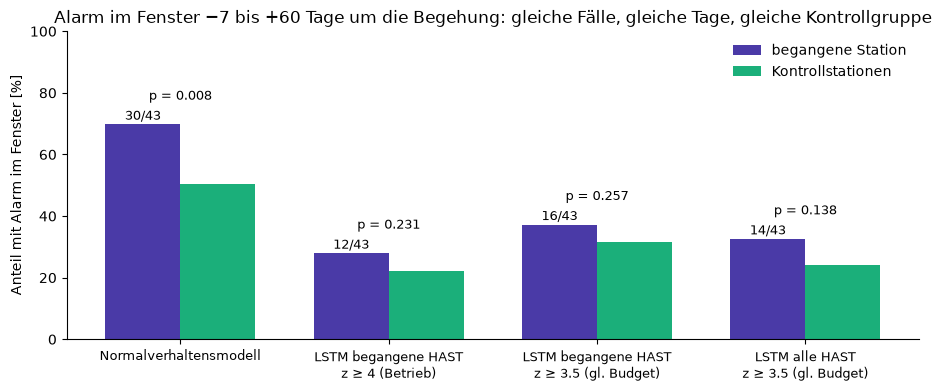

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(tabelle))
ax.bar(x - 0.18, tabelle["Quote"] * 100, 0.36, color="#4a3aa7", label="begangene Station")
ax.bar(x + 0.18, tabelle["Kontrollquote"] * 100, 0.36, color="#1baf7a", label="Kontrollstationen")
for xi, (k, n, p) in enumerate(zip(tabelle["Treffer"], tabelle["Fälle"], tabelle["p (einseitig)"])):
    ax.text(xi - 0.18, tabelle["Quote"].iloc[xi] * 100 + 1.5, f"{k}/{n}", ha="center", fontsize=9)
    ax.text(xi, max(tabelle["Quote"].iloc[xi], tabelle["Kontrollquote"].iloc[xi]) * 100 + 8, f"p = {p:.3f}", ha="center", fontsize=9)
ax.set_xticks(x, tabelle["Wächter"].str.replace(", ", "\n"), fontsize=9)
ax.set_ylabel("Anteil mit Alarm im Fenster [%]")
ax.set_ylim(0, 100)
ax.set_title("Alarm im Fenster −7 bis +60 Tage um die Begehung: gleiche Fälle, gleiche Tage, gleiche Kontrollgruppe")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was machen die beiden Zellen?**
- Wenden dieselbe `trefferpruefung()` auf vier Alarmlisten an, alle auf den gemeinsamen
  Stationen und Tagen. Die erste Zeile prüft, dass alle vier dieselben Fälle bewerten.
- Das Bild stellt je Wächter die Trefferquote an den begangenen Stationen (violett) neben
  die Quote an den Kontrollstationen (grün). Entscheidend ist der Abstand zwischen beiden,
  nicht die Höhe der Balken.

**Ergebnis**

Alle **43** Fälle aus Notebook 17 lassen sich auf der gemeinsamen Grundlage bewerten. Weil das LSTM jetzt 87 Stationen überwacht, fällt keiner heraus (in der vorigen Fassung waren es 32 von 41).

| Wächter | Treffer | Kontrolle | Hebel | p |
|---|---|---|---|---|
| Normalverhaltensmodell | **30/43 (70 %)** | 50 % | 1,39 | **0,008** |
| LSTM begangene HAST, z ≥ 4 | 12/43 (28 %) | 22 % | 1,26 | 0,23 |
| LSTM begangene HAST, gleiches Budget | 16/43 (37 %) | 32 % | 1,18 | 0,26 |
| LSTM alle HAST, gleiches Budget | 14/43 (33 %) | 24 % | 1,34 | 0,14 |

- **Sebs Ergebnis hält auf der gemeinsamen Grundlage** und ist dort sogar deutlicher (p = 0,008 gegen 0,017 mit allen seinen Tagen).
- **Keines der LSTM ist belegt.** Der Hebel, also wie viel öfter eine begangene Station alarmiert als eine Kontrollstation, liegt beim LSTM bei 1,2 bis 1,3, bei Seb bei 1,4. Dazu ist Sebs Grundquote höher: Bei fast gleicher Alarmmenge haben mehr Fenster mindestens einen Alarm, seine Alarme liegen also weniger gehäuft. Bei 43 Fällen reicht das bei ihm für einen Beleg, beim LSTM nicht.
- **Für die Praxis zählt die erste Spalte:** Bei gleich vielen Alarmen bemerkt Sebs Modell 30 von 43 Begehungen, das LSTM 16.

In [10]:
fall_vergleich = pd.DataFrame({name: t.set_index(["zaehler", "datum"])["treffer"] for name, t in ergebnisse.items()})
seb_name, lstm_name = list(ergebnisse)[0], list(ergebnisse)[2]
nur_seb = int((fall_vergleich[seb_name] & ~fall_vergleich[lstm_name]).sum())
nur_lstm = int((~fall_vergleich[seb_name] & fall_vergleich[lstm_name]).sum())
p_mcnemar = stats.binomtest(nur_lstm, nur_seb + nur_lstm, 0.5).pvalue
print(f"Nur Seb: {nur_seb}, nur LSTM: {nur_lstm}  ->  McNemar (exakt, zweiseitig): p = {p_mcnemar:.3f}")
pd.crosstab(fall_vergleich[seb_name].map({True: "Seb: Alarm", False: "Seb: kein Alarm"}),
            fall_vergleich[lstm_name].map({True: "LSTM: Alarm", False: "LSTM: kein Alarm"}), margins=True, margins_name="Summe")

Nur Seb: 15, nur LSTM: 1  ->  McNemar (exakt, zweiseitig): p = 0.001


"LSTM begangene HAST, z ≥ 3.5 (gl. Budget)",LSTM: Alarm,LSTM: kein Alarm,Summe
Normalverhaltensmodell,,,
Seb: Alarm,15,15,30
Seb: kein Alarm,1,12,13
Summe,16,27,43


**Was macht diese Zelle?**
- Stellt Fall für Fall gegenüber, ob Seb und das LSTM (bei gleichem Budget) die Begehung
  bemerkt haben. Die Diagonale sind Fälle, bei denen beide gleich urteilen.
- Der McNemar-Test schaut nur auf die Fälle, in denen die beiden sich uneinig sind: Wären
  beide gleich gut, müssten sich diese Fälle etwa hälftig verteilen.

**Ergebnis**

- 15 Begehungen bemerken beide, 12 keiner.
- **15 bemerkt nur Seb, 1 nur das LSTM.** Der McNemar-Test liegt bei p = 0,001. Fall für Fall ist Sebs Vorsprung damit belegt (in der vorigen Fassung mit 32 Fällen war er es knapp nicht, p = 0,057).
- Zusammen kämen beide auf 31 von 43. Das LSTM fügt Sebs Modell an den Begehungen nur einen Fall hinzu.

### Hängt das Ergebnis am Fenster?

Notebook 21 hat 14 Tage nach der Begehung geschaut, Notebook 17 60 Tage. Ein kurzes Fenster
macht den Abstand zur Kontrolle größer, weil zufällige Alarme dort seltener hineinfallen.
Deshalb dieselbe Prüfung für beide Wächter mit drei Fenstern.

In [11]:
gleiches_budget = {name: als_tage(a) for name, a in alarmlisten.items() if "Betrieb" not in name}
zeilen = []
for nach in (14, 30, 60):
    for name, alarme in gleiches_budget.items():
        b = bilanz(trefferpruefung(alarme, beobachtet_gemeinsam, gemeinsame_stationen, faelle, nach=nach), name)
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", **b})
pd.DataFrame(zeilen).set_index(["Fenster", "Wächter"]).round(3)

Fälle  Treffer  Quote  Kontrollquote  Hebel  p (einseitig)
Fenster         Wächter                                                                                              
−7 bis +14 Tage Normalverhaltensmodell                        39       14  0.359          0.219  1.636          0.033
                LSTM begangene HAST, z ≥ 3.5 (gl. Budget)     39        7  0.179          0.173  1.038          0.523
                LSTM alle HAST, z ≥ 3.5 (gl. Budget)          39        7  0.179          0.161  1.113          0.444
−7 bis +30 Tage Normalverhaltensmodell                        43       23  0.535          0.351  1.522          0.010
                LSTM begangene HAST, z ≥ 3.5 (gl. Budget)     43        9  0.209          0.206  1.016          0.539
                LSTM alle HAST, z ≥ 3.5 (gl. Budget)          43       10  0.233          0.202  1.150          0.367
−7 bis +60 Tage Normalverhaltensmodell                        43       30  0.698          0.503  1.387          0.008
                LSTM begangene HAST, z ≥ 3.5 (gl. Budget)     43       16  0.372          0.315  1.181          0.257
                LSTM alle HAST, z ≥ 3.5 (gl. Budget)          43       14  0.326          0.242  1.343          0.138

**Was macht diese Zelle?**
- Wiederholt die Prüfung mit einem Fenster bis 14, 30 und 60 Tage nach der Begehung, für Seb
  und die beiden LSTM mit gleichem Alarmbudget. Alles andere bleibt gleich.

**Ergebnis**

- **Sebs Modell reagiert schnell:** In den ersten 14 Tagen nach der Begehung alarmiert es bei 36 % der Fälle gegen 22 % bei den Kontrollen (p = 0,033). Mit 30 und 60 Tagen bleibt es belegt und wird deutlicher (p = 0,010 und 0,008).
- **Das LSTM zeigt in 14 Tagen gar kein Signal:** 18 % gegen 17 % bzw. 18 % gegen 16 %. Erst mit langen Fenstern liegt es leicht über der Kontrolle, belegt ist es in keinem Fenster.
- In der vorigen Fassung zeigte der erste Blick in Notebook 21 noch 24–29 % gegen 8 % in 14 Tagen. Woran das lag, zeigt der nächste Abschnitt.

### Wer sind die Kontrollstationen?

Sebs Kontrollgruppe nimmt jede Station, die in den 60 Tagen vor dem Fenster nicht begangen
wurde. Das sind nie begangene Stationen, aber auch Stationen, deren Begehung länger zurückliegt
oder erst später kommt. Notebook 21 hat dagegen nur nie begangene Stationen als Kontrolle
genommen. Die Zelle rechnet die Kontrollquote getrennt für beide Gruppen.

In [12]:
nie_begangen = [z for z in gemeinsame_stationen if z not in termine]
begangen = [z for z in gemeinsame_stationen if z in termine]
print(f"Gemeinsame Stationen: {len(nie_begangen)} nie begangen, {len(begangen)} begangen")
zeilen = []
for nach in (14, 60):
    for name, alarme in gleiches_budget.items():
        fall_quote = bilanz(trefferpruefung(alarme, beobachtet_gemeinsam, gemeinsame_stationen, faelle, nach=nach), name)["Quote"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Wächter": name, "begangene Station (Fall)": fall_quote,
                       "Kontrolle: nie begangen": trefferpruefung(alarme, beobachtet_gemeinsam, nie_begangen, faelle, nach=nach)["kontrollquote"].mean(),
                       "Kontrolle: andere begangene": trefferpruefung(alarme, beobachtet_gemeinsam, begangen, faelle, nach=nach)["kontrollquote"].mean()})
pd.DataFrame(zeilen).set_index(["Fenster", "Wächter"]).round(3)

Gemeinsame Stationen: 38 nie begangen, 48 begangen


begangene Station (Fall)  Kontrolle: nie begangen  Kontrolle: andere begangene
Fenster         Wächter                                                                                                                  
−7 bis +14 Tage Normalverhaltensmodell                                        0.359                    0.251                        0.160
                LSTM begangene HAST, z ≥ 3.5 (gl. Budget)                     0.179                    0.084                        0.368
                LSTM alle HAST, z ≥ 3.5 (gl. Budget)                          0.179                    0.134                        0.230
−7 bis +60 Tage Normalverhaltensmodell                                        0.698                    0.521                        0.455
                LSTM begangene HAST, z ≥ 3.5 (gl. Budget)                     0.372                    0.245                        0.573
                LSTM alle HAST, z ≥ 3.5 (gl. Budget)                          0.326                    0.217                        0.333

**Was macht diese Zelle?**
- Teilt die gemeinsamen Stationen in nie begangene und begangene.
- Ruft dieselbe `trefferpruefung()` zweimal auf, einmal nur mit nie begangenen und einmal nur mit
  begangenen Stationen als Kontrolle. Die Trefferquote der Fälle bleibt dabei gleich, nur die
  Vergleichsgruppe ändert sich.

**Ergebnis**

- **Sebs Modell behandelt alle Stationen ähnlich:** Nie begangene Stationen alarmieren sogar etwas öfter als andere begangene (25 % gegen 16 % in 14 Tagen, 52 % gegen 46 % in 60 Tagen). Nur die gerade begangene Station sticht heraus (36 % bzw. 70 %).
- **Das LSTM auf den begangenen HAST alarmiert an begangenen Stationen viel öfter**, egal ob deren Begehung im Fenster liegt oder nicht: 37 % gegen 8 % in 14 Tagen, 57 % gegen 25 % in 60 Tagen. Die gerade begangene Station (18 % bzw. 37 %) liegt sogar unter den anderen begangenen.
- **Damit erklärt sich der erste Blick in Notebook 21:** Dort waren nur nie begangene Stationen die Kontrolle. Gemessen wurde also vor allem der Unterschied „begangen gegen nie begangen“, nicht „nach der Begehung gegen ohne“.
- **Ein Teil davon ist die Vorgabe:** Das Netz hat die begangenen Stationen gelernt und sagt sie genauer vorher. Ihre normale Schwankung ist deshalb kleiner, und der Wächter reagiert dort empfindlicher. Beim Netz auf allen HAST schrumpft der Abstand (23 % gegen 13 % bzw. 33 % gegen 22 %), verschwindet aber nicht. Der Rest passt zu Notebook 21: Die begangenen Stationen haben sich im Winter 24/25 stärker verändert als die meisten nie begangenen.

### Wie groß ist die Veränderung nach einer Begehung?

Beide Wächter rechnen in z-Werten, also in Vielfachen der normalen Schwankung einer Station.
Wie weit verschiebt sich dieser z-Wert im Mittel, wenn man die 30 gemeinsamen Tage vor der
Begehung mit den 30 Tagen danach vergleicht?

In [13]:
seb_breit = (seb_tage[~seb_tage["referenz"]].pivot_table(index=["zaehler", "datum"], columns="kanal", values="z")
             .rename(columns={"kwh_pro_m3": "Seb: Abkühlung", "log_volumen": "Seb: Tagesvolumen"}).reset_index())
lstm_breit = lstm.rename(columns={"tag": "datum", "z_rl": "LSTM: Rücklauf", "z_fluss": "LSTM: Nachtdurchfluss"})
z_tage = gemeinsam.merge(seb_breit, on=["zaehler", "datum"]).merge(
    lstm_breit[["zaehler", "datum", "LSTM: Rücklauf", "LSTM: Nachtdurchfluss"]], on=["zaehler", "datum"])
KANAL_SPALTEN = ["Seb: Abkühlung", "Seb: Tagesvolumen", "LSTM: Rücklauf", "LSTM: Nachtdurchfluss"]

zeilen = []
for fall in faelle.itertuples(index=False):
    t = z_tage[z_tage["zaehler"] == fall.zaehler]
    tage_seit = (t["datum"] - fall.datum).dt.days
    vor, nach = t[(tage_seit >= -30) & (tage_seit < 0)], t[(tage_seit >= 0) & (tage_seit < 30)]
    if len(vor) >= 5 and len(nach) >= 5:
        zeilen.append({"zaehler": fall.zaehler, **{k: nach[k].mean() - vor[k].mean() for k in KANAL_SPALTEN}})
verschiebung = pd.DataFrame(zeilen).set_index("zaehler")
print(f"{len(verschiebung)} Fälle mit je mindestens 5 gemeinsamen Tagen vor und nach der Begehung")
pd.DataFrame({"Median |Verschiebung| (z)": verschiebung.abs().median(),
              "Anteil Fälle mit |Verschiebung| ≥ 1": (verschiebung.abs() >= 1).mean(),
              "Anteil Fälle mit |Verschiebung| ≥ 3,5": (verschiebung.abs() >= 3.5).mean()}).round(2)

28 Fälle mit je mindestens 5 gemeinsamen Tagen vor und nach der Begehung


,Median |Verschiebung| (z),Anteil Fälle mit |Verschiebung| ≥ 1,"Anteil Fälle mit |Verschiebung| ≥ 3,5"
Seb: Abkühlung,0.51,0.07,0.00
Seb: Tagesvolumen,0.57,0.25,0.04
LSTM: Rücklauf,0.46,0.04,0.00
LSTM: Nachtdurchfluss,0.55,0.18,0.00


**Was macht diese Zelle?**
- Legt die z-Werte beider Wächter für jeden gemeinsamen Tag nebeneinander (`z_tage`).
- Rechnet je Fall den mittleren z-Wert in den 30 Tagen nach der Begehung minus den in den 30
  Tagen davor, je Kanal. Das ist die anhaltende Veränderung, die die Begehung hinterlassen hat.
- Viele Begehungen liegen Anfang September, davor gibt es kaum Heiztage. Deshalb bleiben hier
  nur die Fälle mit genug Tagen auf beiden Seiten.

**Ergebnis**

- **Die Veränderung nach einer Begehung ist klein**, bei beiden Wächtern gleich: im Median 0,5 bis 0,6 Streuungen, in allen vier Kanälen. Nur 4 bis 25 % der Fälle verschieben sich um mehr als eine Streuung, ein einziger um 3,5 (beim Tagesvolumen).
- **Das erklärt den Unterschied besser als das Modell selbst.** Beide sehen die Veränderung gleich groß, entscheidend ist die Alarmregel:
  - Sebs **CUSUM** zählt jeden Tag auf, um wie viel der z-Wert über 0,5 liegt, und alarmiert bei einer Summe von 5. Eine anhaltende Verschiebung um eine Streuung löst so nach etwa zehn Heiztagen aus.
  - Die Regel des LSTM verlangt **3,5 Streuungen an zwei Tagen hintereinander**. Sie fängt große, plötzliche Sprünge, wie den Bypass von 150 l/h, und keine kleinen Dauerverschiebungen.
- Dazu kommt vermutlich, dass das LSTM die letzten sieben Tage als Eingang bekommt. Eine bleibende Veränderung wird so Teil seiner Erwartung. In Notebook 21 zeigt sich das beim verstellten Sollwert, der nur zu 19 % gefunden wird.

### Und wenn das LSTM auch die Sommertage benutzen darf?

Bisher zählen nur Heiztage, weil Sebs Modell nur dort rechnet. Das LSTM überwacht aber jeden
Tag. Hier dieselbe Prüfung für das LSTM auf **allen** seinen Tagen ab Juni 2024, mit der
Betriebsschwelle z ≥ 4. Das ist kein fairer Vergleich mehr mit Seb, sondern zeigt, was das
LSTM in seiner eigenen Einstellung leistet.

In [14]:
lstm_alle_tage = {z: g["tag"] for z, g in lstm_tage.groupby("zaehler")}
lstm_alarme_alle = lstm_alarme(4)
lstm_alarme_alle = lstm_alarme_alle[lstm_alarme_alle["datum"] >= AB]
alle = trefferpruefung(als_tage(lstm_alarme_alle), lstm_alle_tage, gemeinsame_stationen, faelle)
print(f"Alarme ab Juni 2024 auf allen Tagen: {len(lstm_alarme_alle[lstm_alarme_alle['zaehler'].isin(gemeinsame_stationen)])} "
      f"(nur Heiztage: {len(auf_gemeinsamen_tagen(lstm_alarme(4)))})")
pd.DataFrame([bilanz(ergebnisse["LSTM begangene HAST, z ≥ 4 (Betrieb)"], "LSTM begangene HAST, z ≥ 4, nur Heiztage"),
              bilanz(alle, "LSTM begangene HAST, z ≥ 4, alle Tage")]).round(3)

Alarme ab Juni 2024 auf allen Tagen: 264 (nur Heiztage: 148)


,Wächter,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,"LSTM begangene HAST, z ≥ 4, nur Heiztage",43,12,0.279,0.222,1.257,0.231
1,"LSTM begangene HAST, z ≥ 4, alle Tage",43,15,0.349,0.291,1.201,0.246


**Was macht diese Zelle?**
- Nimmt als überwachte Tage alle Tage des LSTM ab Juni 2024 und alle seine Alarme dort, auch
  im Sommer. Fälle, Fenster und Kontrollregel bleiben gleich.

**Ergebnis**

- Mit allen Tagen gibt das LSTM mehr Alarme (264 statt 148 an den gemeinsamen Stationen) und trifft **15 statt 12 von 43** Begehungen. Die zusätzlichen Alarme an warmen Tagen fallen aber genauso bei den Kontrollen an (29 % statt 22 %), der Hebel sinkt sogar (1,20 statt 1,26).
- Der Sommer hilft bei diesen Fällen also nicht. Die meisten Begehungen lagen Anfang September, das Fenster reicht in die Heizzeit hinein, und dort sieht auch Sebs Modell zu.

## 7 · Der bekannte Fall 68956351

Bei dieser Station stand das Ventil rund drei Jahre offen; am 09.09.2024 wurde der
Stellmotor getauscht. Beide Wächter sollten das als Veränderung melden.

In [15]:
FALL, DATUM = 68956351, pd.Timestamp("2024-09-09")
s = seb_alarme[(seb_alarme["zaehler"] == FALL) & (seb_alarme["datum"] >= DATUM - pd.Timedelta(days=60))
               & (seb_alarme["datum"] <= DATUM + pd.Timedelta(days=60))]
l = lstm_alarme(4)
l = l[(l["zaehler"] == FALL) & (l["datum"] >= DATUM - pd.Timedelta(days=60)) & (l["datum"] <= DATUM + pd.Timedelta(days=60))]
pd.DataFrame({
    "Wächter": ["Normalverhaltensmodell"] * len(s) + ["Prognose-LSTM (z ≥ 4)"] * len(l),
    "Alarm am": list(s["datum"]) + list(l["datum"]),
    "Kanal": list(s["kanal"].map({"kwh_pro_m3": "Abkühlung", "log_volumen": "Tagesvolumen"})) + ["Rücklauf / Nachtdurchfluss"] * len(l),
}).assign(**{"Tage nach der Begehung": lambda d: (d["Alarm am"] - DATUM).dt.days})

,Wächter,Alarm am,Kanal,Tage nach der Begehung
0,Normalverhaltensmodell,2024-09-11,Abkühlung,2
1,Prognose-LSTM (z ≥ 4),2024-09-16,Rücklauf / Nachtdurchfluss,7
2,Prognose-LSTM (z ≥ 4),2024-10-01,Rücklauf / Nachtdurchfluss,22
3,Prognose-LSTM (z ≥ 4),2024-10-12,Rücklauf / Nachtdurchfluss,33


**Was macht diese Zelle?**
- Listet alle Alarme beider Wächter in den 60 Tagen vor und nach der Begehung dieser Station.

**Ergebnis**

- **Beide Wächter bemerken den Ventiltausch.** Sebs Modell meldet sich nach **2 Tagen** über die Abkühlung, das LSTM nach **7 Tagen**.
- Das LSTM meldet dieselbe Station danach noch zweimal (nach 22 und 33 Tagen). Das ist dieselbe Veränderung, die es immer wieder sieht, weil es die Station nur von vor dem Tausch kennt. Notebook 21 empfiehlt deshalb, nach einem bekannten Eingriff neu zu kalibrieren.
- Bei dem einen Fall mit großem Sprung (Rücklauf am vierten Tag 15 Streuungen unter der Erwartung) funktioniert also auch die Schwellenregel, nur langsamer.

## 8 · Was nur einer der beiden kann

Der Vergleich an den Begehungen läuft auf Heiztagen, weil Sebs Modell nur dort rechnet.
Zwei Dinge lassen sich deshalb nur für einen Wächter prüfen:

| | Normalverhaltensmodell | Prognose-LSTM |
|---|---|---|
| Sommer und Übergangszeit | rechnet nicht | überwacht; ein offenes Ventil ist nachts im Sommer am deutlichsten |
| Eingerechnete Fehler mit bekannter Fehlalarmrate (NB 21) | nicht geprüft | Bypass 150 l/h zu 84 %, 50 l/h zu 55 % bei 8 % Fehlalarmen |
| Wirkung der Begehungen mit Kontrollgruppe (NB 17) | Tagesvolumen −11 % gegenüber der Kontrolle (p = 0,026) | nicht gerechnet |
| Flottenvergleich (dauerhaft schlechte Stationen) | ja, Normkennzahl je Station | nein; dafür die Fehlererkennung in NB 20/22 |

## Zusammenfassung & Bewertung

### Was dieses Notebook geliefert hat

- **Sebs Prüfung aus Notebook 17 als Funktion**, Fall für Fall gegen seine Zahlen geprüft (30/43, p = 0,017).
- **Ein Vergleich unter gleichen Bedingungen:**
  - dieselben 86 Stationen und Heiztage ab Juni 2024,
  - dieselben 43 Begehungen, dasselbe Fenster und dieselbe Kontrollgruppe,
  - dasselbe Alarmbudget.

| Prüfung | Normalverhaltensmodell | Prognose-LSTM (begangene HAST, gleiches Budget) |
|---|---|---|
| Begehungen bemerkt (−7 bis +60 Tage) | **30/43 (70 %)** gegen 50 %, p = 0,008 | 16/43 (37 %) gegen 32 %, p = 0,26 |
| In den ersten 14 Tagen | **36 % gegen 22 %, p = 0,033** | 18 % gegen 17 %, kein Signal |
| Fall für Fall | 15 nur Seb | 1 nur LSTM (McNemar p = 0,001) |
| Netz auf allen HAST | – | 14/43 (33 %) gegen 24 %, p = 0,14 |
| Kontrollstationen | ähnlich oft bei nie und anderen begangenen | an begangenen deutlich öfter (37 % gegen 8 % in 14 Tagen) |
| Verschiebung nach Begehung | im Median 0,5–0,6 Streuungen | im Median 0,5–0,6 Streuungen |
| Fall 68956351 | Alarm nach 2 Tagen | nach 7 Tagen, danach noch zweimal |

### Wie das Ergebnis einzuordnen ist

- **Die beiden Wächter sind jetzt vergleichbar, und an den Begehungen liegt Sebs Normalverhaltensmodell vorne.** Es bemerkt bei gleich vielen Alarmen mehr Begehungen, und zwar schon in den ersten zwei Wochen. Für das LSTM ist in keiner Einstellung ein Signal belegt.
- **Der Grund liegt in der Alarmregel, nicht im Netz.** Eine Begehung verschiebt den Betrieb nur um etwa eine halbe Streuung. CUSUM sammelt solche kleinen Verschiebungen auf, eine Schwelle von 3,5 Streuungen an zwei Tagen sieht sie nicht. Das LSTM ist für große, plötzliche Fehler gebaut. Dafür hat Notebook 21 es mit eingerechneten Fehlern geprüft: Bypass 150 l/h zu 84 %.
- **Der erste Blick in Notebook 21 war in der vorigen Fassung zu optimistisch.** „24–29 % gegen 8 %“ verglich begangene mit nie begangenen Stationen. Mit Sebs Kontrollgruppe blieb davon nichts, und in dieser Fassung zeigt auch der erste Blick keinen Vorsprung mehr (11–17 % gegen 13 %).
- **Die Vorgabe „nur begangene HAST“ färbt den Wächter:** Er ist an den gelernten Stationen empfindlicher. Das Netz auf allen HAST hat unter den LSTM den höchsten Hebel (1,34), ist aber auch nicht belegt.
- **Was dieser Vergleich nicht sagt:**
  - Begehungen sind Eingriffe, meist Verbesserungen, und keine plötzlich auftretenden Fehler. Ob Sebs Modell einen plötzlichen Bypass so gut findet wie das LSTM, ist nicht gerechnet. Seine synthetischen Tests in Notebook 17 galten der Form der Kennlinie und den Fehlalarmen, Trefferquoten für eingerechnete Fehler gibt es dort nicht.
  - Den Sommer überwacht nur das LSTM, für die Begehungsfälle hier bringt er aber nichts.

**Kurz:** Für das, was die Daten prüfen lassen (Veränderungen nach Begehungen in der Heizzeit), ist Sebs Normalverhaltensmodell der bessere Wächter. Das Prognose-LSTM ist ein Werkzeug für plötzliche, große Fehler und für den Sommer. Diese Stärke ist bisher nur mit eingerechneten Fehlern gezeigt, nicht an echten Fällen.